In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import accuracy_score,confusion_matrix,classification_report,recall_score,precision_score,f1_score


In [2]:
df = pd.read_csv("email.csv", encoding="latin-1")

print("Dataset Shape:", df.shape)
print("Column Names:", df.columns.tolist())
print(df.head())

Dataset Shape: (5573, 2)
Column Names: ['Category', 'Message']
  Category                                            Message
0      ham  Go until jurong point, crazy.. Available only ...
1      ham                      Ok lar... Joking wif u oni...
2     spam  Free entry in 2 a wkly comp to win FA Cup fina...
3      ham  U dun say so early hor... U c already then say...
4      ham  Nah I don't think he goes to usf, he lives aro...


In [3]:
df = df.rename(columns={
    "Category": "label",
    "Message": "message"
})

print(df.columns.tolist())

['label', 'message']


In [4]:
df = df.loc[:, ~df.columns.astype(str).str.contains("^Unnamed")]

df = df.dropna(subset=["label", "message"]).copy()

df["label"] = df["label"].astype(str).str.strip().str.lower()

df = df[df["label"].isin(["ham", "spam"])].copy()

df["message"] = df["message"].astype(str).str.strip()
df = df[df["message"] != ""]

df["label"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

df = df.reset_index(drop=True)

print("Cleaned Dataset Shape:", df.shape)
print("\nLabel Counts:")
print(df["label"].value_counts())

print("\nMissing Values:")
print(df.isnull().sum())

Cleaned Dataset Shape: (5572, 2)

Label Counts:
label
0    4825
1     747
Name: count, dtype: int64

Missing Values:
label      0
message    0
dtype: int64


In [5]:
X = df["message"]
y = df["label"]

print("Total Messages:", len(X))
print("Total Labels:", len(y))

Total Messages: 5572
Total Labels: 5572


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 4457
Testing Samples: 1115


In [7]:
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=10000
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training Feature Shape:", X_train_tfidf.shape)
print("Testing Feature Shape:", X_test_tfidf.shape)

Training Feature Shape: (4457, 7429)
Testing Feature Shape: (1115, 7429)


In [8]:
model_lr = LogisticRegression(max_iter=1000)

model_lr.fit(X_train_tfidf, y_train)

y_pred_lr = model_lr.predict(X_test_tfidf)

print("Logistic Regression Model Trained Successfully")

Logistic Regression Model Trained Successfully


In [9]:
print("Accuracy:", accuracy_score(y_test, y_pred_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=["Ham", "Spam"]
))
print("\nPrecision:", precision_score(y_test, y_pred_lr, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_lr, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_lr, zero_division=0))

Accuracy: 0.9668161434977578

Confusion Matrix:
[[966   0]
 [ 37 112]]

Classification Report:
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       966
        Spam       1.00      0.75      0.86       149

    accuracy                           0.97      1115
   macro avg       0.98      0.88      0.92      1115
weighted avg       0.97      0.97      0.96      1115


Precision: 1.0
Recall: 0.7516778523489933
F1 Score: 0.8582375478927203


In [10]:
from sklearn.naive_bayes import MultinomialNB

model_nb = MultinomialNB()

model_nb.fit(X_train_tfidf, y_train)

y_pred_nb = model_nb.predict(X_test_tfidf)

print("Naive Bayes Model Trained Successfully")

Naive Bayes Model Trained Successfully


In [11]:
print("Accuracy:", accuracy_score(y_test, y_pred_nb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_nb))

print("\nPrecision:", precision_score(y_test, y_pred_nb, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_nb, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_nb, zero_division=0))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_nb,
    target_names=["Ham", "Spam"],
    zero_division=0
))

Accuracy: 0.9695067264573991

Confusion Matrix:
[[966   0]
 [ 34 115]]

Precision: 1.0
Recall: 0.7718120805369127
F1 Score: 0.8712121212121212

Classification Report:
              precision    recall  f1-score   support

         Ham       0.97      1.00      0.98       966
        Spam       1.00      0.77      0.87       149

    accuracy                           0.97      1115
   macro avg       0.98      0.89      0.93      1115
weighted avg       0.97      0.97      0.97      1115



In [12]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Naive Bayes"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_nb)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr, zero_division=0),
        precision_score(y_test, y_pred_nb, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr, zero_division=0),
        recall_score(y_test, y_pred_nb, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_lr, zero_division=0),
        f1_score(y_test, y_pred_nb, zero_division=0)
    ]
})

print(comparison)

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.966816        1.0  0.751678  0.858238
1          Naive Bayes  0.969507        1.0  0.771812  0.871212


In [13]:
email = ["Congratulations! You have won a free prize. Claim now!"]

email_tfidf = tfidf.transform(email)

prediction = model_lr.predict(email_tfidf)

if prediction[0] == 1:
    print("Prediction: Spam")
else:
    print("Prediction: Ham (Not Spam)")

Prediction: Spam


In [14]:
pip install transformers torch

Note: you may need to restart the kernel to use updated packages.


In [18]:
import os
import shutil

cache_path = os.path.expanduser(
    "~/.cache/huggingface/hub/models--distilbert-base-uncased"
)

if os.path.exists(cache_path):
    shutil.rmtree(cache_path)
    print("Old DistilBERT cache cleared")
else:
    print("No old DistilBERT cache found")

Old DistilBERT cache cleared


In [21]:
from huggingface_hub import hf_hub_download
import os

model_name = "distilbert-base-uncased"
model_path = "./distilbert_model_files"

os.makedirs(model_path, exist_ok=True)

files_to_download = [
    "config.json",
    "model.safetensors",
    "tokenizer.json",
    "tokenizer_config.json",
    "vocab.txt",
    "special_tokens_map.json"
]

for file_name in files_to_download:
    try:
        hf_hub_download(
            repo_id=model_name,
            filename=file_name,
            local_dir=model_path
        )
        print(file_name, "downloaded successfully")
    except Exception as e:
        print("Error downloading", file_name, ":", e)

print("Download step finished.")

config.json downloaded successfully
model.safetensors downloaded successfully
tokenizer.json downloaded successfully
tokenizer_config.json downloaded successfully
vocab.txt downloaded successfully
Error downloading special_tokens_map.json : 404 Client Error. (Request ID: Root=1-6acb18e1-2941888008294b365688a21b;93b64e00-1069-434f-80b0-f007457a9c64)

Entry Not Found for url: https://huggingface.co/distilbert-base-uncased/resolve/main/special_tokens_map.json.
Download step finished.


In [22]:
from transformers import AutoTokenizer

model_path = "./distilbert_model_files"

tokenizer = AutoTokenizer.from_pretrained(
    model_path,
    use_fast=True
)

print("Tokenizer loaded successfully")

Tokenizer loaded successfully


In [23]:
import torch
from transformers import AutoModelForSequenceClassification

device = torch.device("cpu")

model = AutoModelForSequenceClassification.from_pretrained(
    model_path,
    num_labels=2
)

model = model.to(device)

print("Model loaded successfully")
print("Device:", device)

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at ./distilbert_model_files and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Model loaded successfully
Device: cpu


In [24]:
for param in model.distilbert.parameters():
    param.requires_grad = False

for layer in model.distilbert.transformer.layer[4:6]:
    for param in layer.parameters():
        param.requires_grad = True


for param in model.pre_classifier.parameters():
    param.requires_grad = True

for param in model.classifier.parameters():
    param.requires_grad = True

print("First four transformer layers frozen")
print("Last two transformer layers unfrozen")
print("Classification head trainable")

First four transformer layers frozen
Last two transformer layers unfrozen
Classification head trainable


In [25]:
import pandas as pd

df = pd.read_csv("email.csv")

print(df.head())
print(df.columns)
print(df.shape)

  Category                                            Message
0      ham  Go until jurong point, crazy.. Available only ...
1      ham                      Ok lar... Joking wif u oni...
2     spam  Free entry in 2 a wkly comp to win FA Cup fina...
3      ham  U dun say so early hor... U c already then say...
4      ham  Nah I don't think he goes to usf, he lives aro...
Index(['Category', 'Message'], dtype='object')
(5573, 2)


In [26]:
print("Columns:", df.columns.tolist())

text_candidates = ["text", "email", "message", "content", "EmailText"]
label_candidates = ["label", "category", "spam", "target", "EmailType"]

text_column = next(
    (col for col in text_candidates if col in df.columns),
    None
)

label_column = next(
    (col for col in label_candidates if col in df.columns),
    None
)

if text_column is None or label_column is None:
    print("Please check the column names printed above.")
else:
    df = df[[text_column, label_column]].dropna().copy()
    df.columns = ["text", "label"]

    print(df.head())
    print(df["label"].value_counts())

Columns: ['Category', 'Message']
Please check the column names printed above.


In [28]:

df = pd.read_csv("email.csv")

df = df[["Message", "Category"]].dropna().copy()

df.columns = ["text", "label"]

print(df.head())
print(df["label"].unique())
print(df["label"].value_counts())

                                                text label
0  Go until jurong point, crazy.. Available only ...   ham
1                      Ok lar... Joking wif u oni...   ham
2  Free entry in 2 a wkly comp to win FA Cup fina...  spam
3  U dun say so early hor... U c already then say...   ham
4  Nah I don't think he goes to usf, he lives aro...   ham
['ham' 'spam' '{"mode":"full"']
label
ham               4825
spam               747
{"mode":"full"       1
Name: count, dtype: int64


In [29]:
print(df["label"].unique())


['ham' 'spam' '{"mode":"full"']


In [30]:
df["label"] = df["label"].str.strip().str.lower().map({
    "ham": 0,
    "spam": 1
})

df = df.dropna().copy()
df["label"] = df["label"].astype(int)

print(df["label"].value_counts())
print("Labels converted successfully")

label
0    4825
1     747
Name: count, dtype: int64
Labels converted successfully


In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df["text"].tolist(),
    df["label"].tolist(),
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4457
Testing samples: 1115


In [32]:
train_encodings = tokenizer(
    X_train,
    truncation=True,
    padding="max_length",
    max_length=128,
    return_tensors="pt"
)

test_encodings = tokenizer(
    X_test,
    truncation=True,
    padding="max_length",
    max_length=128,
    return_tensors="pt"
)

print("Training tokenization completed")
print("Testing tokenization completed")

Training tokenization completed
Testing tokenization completed


In [33]:
from torch.utils.data import Dataset, DataLoader
import torch

class EmailDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        item = {
            key: value[index]
            for key, value in self.encodings.items()
        }

        item["labels"] = torch.tensor(
            int(self.labels[index]),
            dtype=torch.long
        )

        return item


train_dataset = EmailDataset(train_encodings, y_train)
test_dataset = EmailDataset(test_encodings, y_test)

print("Training dataset:", len(train_dataset))
print("Testing dataset:", len(test_dataset))

Training dataset: 4457
Testing dataset: 1115


In [34]:
batch_size = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

Training batches: 558
Testing batches: 140


In [35]:
from torch.optim import AdamW

learning_rate = 2e-5

optimizer = AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=learning_rate
)

epochs = 1

print("Learning rate:", learning_rate)
print("Batch size:", batch_size)
print("Epochs:", epochs)

Learning rate: 2e-05
Batch size: 8
Epochs: 1


In [58]:
import time
import torch
import matplotlib.pyplot as plt

train_losses = []
distilbert_training_time = 0

model.train()
start_time = time.time()

for batch in train_loader:
    batch = {
        key: value.to(device)
        for key, value in batch.items()
    }

    optimizer.zero_grad()

    outputs = model(
        input_ids=batch["input_ids"],
        attention_mask=batch["attention_mask"],
        labels=batch["labels"]
    )

    loss = outputs.loss
    loss.backward()
    optimizer.step()

    train_losses.append(loss.item())

distilbert_training_time = time.time() - start_time

print("Training completed.")
print("Batches recorded:", len(train_losses))
print("Training time:", round(distilbert_training_time, 2), "seconds")

Training completed.
Batches recorded: 558
Training time: 846.44 seconds


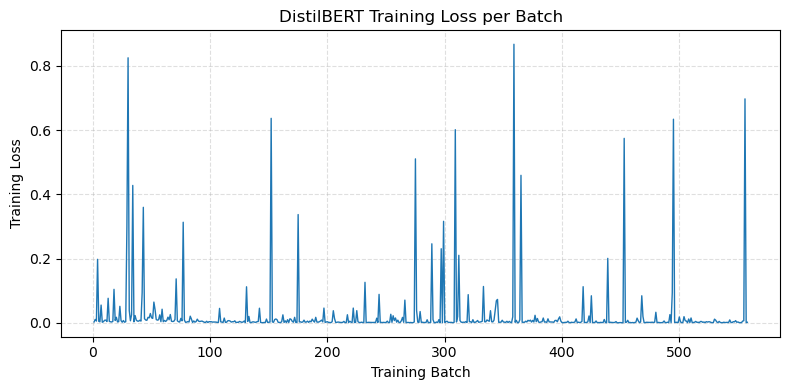

In [59]:
plt.figure(figsize=(8, 4))

plt.plot(
    range(1, len(train_losses) + 1),
    train_losses,
    linewidth=1
)

plt.title("DistilBERT Training Loss per Batch")
plt.xlabel("Training Batch")
plt.ylabel("Training Loss")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [62]:
import numpy as np
import torch

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for batch in test_loader:
        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        labels = batch["labels"]

        outputs = model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"]
        )

        predictions = torch.argmax(
            outputs.logits, dim=1
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )
        all_labels.extend(labels.cpu().numpy())

print("Evaluation completed.")
print("Number of test samples:", len(all_labels))

Evaluation completed.
Number of test samples: 1115


In [63]:
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(
    all_labels, all_predictions, zero_division=0
)
recall = recall_score(
    all_labels, all_predictions, zero_division=0
)
f1 = f1_score(
    all_labels, all_predictions, zero_division=0
)

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(all_labels, all_predictions))

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    zero_division=0
))

Accuracy: 0.9901
Precision: 0.9662
Recall: 0.9597
F1 Score: 0.963

Confusion Matrix:
[[961   5]
 [  6 143]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       966
           1       0.97      0.96      0.96       149

    accuracy                           0.99      1115
   macro avg       0.98      0.98      0.98      1115
weighted avg       0.99      0.99      0.99      1115



In [64]:
import os

save_path = "./distilbert_spam_classifier"
os.makedirs(save_path, exist_ok=True)

model.save_pretrained(save_path)
tokenizer.save_pretrained(save_path)

print("Model and tokenizer saved to:", save_path)

Model and tokenizer saved to: ./distilbert_spam_classifier


In [65]:
import os

save_path = "./distilbert_spam_classifier"
os.makedirs(save_path, exist_ok=True)

model.save_pretrained(save_path)
tokenizer.save_pretrained(save_path)

print("Model saved successfully.")
print("Saved location:", os.path.abspath(save_path))

Model saved successfully.
Saved location: C:\Users\praja\Krutanic\distilbert_spam_classifier


In [66]:
import torch

model.eval()

def predict_spam(message):
    inputs = tokenizer(
        message,
        truncation=True,
        padding=True,
        max_length=128,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        outputs = model(**inputs)
        probabilities = torch.softmax(outputs.logits, dim=1)
        predicted_class = torch.argmax(
            probabilities, dim=1
        ).item()

    label = "SPAM" if predicted_class == 1 else "HAM"
    confidence = probabilities[0, predicted_class].item()

    print("Message:", message)
    print("Prediction:", label)
    print("Confidence:", round(confidence * 100, 2), "%")
    print("-" * 50)

predict_spam("Congratulations! You have won a free prize. Claim now!")
predict_spam("Hi, are we meeting for lunch today?")
predict_spam("URGENT! You have won a cash reward. Call now!")
predict_spam("Please send me the notes from today's class.")

Message: Congratulations! You have won a free prize. Claim now!
Prediction: SPAM
Confidence: 93.55 %
--------------------------------------------------
Message: Hi, are we meeting for lunch today?
Prediction: HAM
Confidence: 99.88 %
--------------------------------------------------
Message: URGENT! You have won a cash reward. Call now!
Prediction: SPAM
Confidence: 66.09 %
--------------------------------------------------
Message: Please send me the notes from today's class.
Prediction: HAM
Confidence: 99.69 %
--------------------------------------------------


In [67]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


part_a_results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred_lr),
        "Precision": precision_score(y_test, y_pred_lr, zero_division=0),
        "Recall": recall_score(y_test, y_pred_lr, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred_lr, zero_division=0)
    },
    {
        "Model": "Naive Bayes",
        "Accuracy": accuracy_score(y_test, y_pred_nb),
        "Precision": precision_score(y_test, y_pred_nb, zero_division=0),
        "Recall": recall_score(y_test, y_pred_nb, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred_nb, zero_division=0)
    }
])


part_b_results = pd.DataFrame([{
    "Model": "DistilBERT",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1
}])


combined_results = pd.concat(
    [part_a_results, part_b_results],
    ignore_index=True
)


print("=" * 65)
print("PART A RESULTS")
print("=" * 65)
print(part_a_results.round(4).to_string(index=False))

print("\n" + "=" * 65)
print("PART B RESULTS")
print("=" * 65)
print(part_b_results.round(4).to_string(index=False))

print("\n" + "=" * 65)
print("COMBINED RESULTS: PART A vs PART B")
print("=" * 65)
print(combined_results.round(4).to_string(index=False))


with pd.ExcelWriter("spam_classification_results.xlsx") as writer:
    part_a_results.to_excel(
        writer, sheet_name="Part A Results", index=False
    )
    part_b_results.to_excel(
        writer, sheet_name="Part B Results", index=False
    )
    combined_results.to_excel(
        writer, sheet_name="Combined Results", index=False
    )

print("\nAll three result tables saved to spam_classification_results.xlsx")

PART A RESULTS
              Model  Accuracy  Precision  Recall  F1 Score
Logistic Regression    0.9668        1.0  0.7517    0.8582
        Naive Bayes    0.9695        1.0  0.7718    0.8712

PART B RESULTS
     Model  Accuracy  Precision  Recall  F1 Score
DistilBERT    0.9901     0.9662  0.9597     0.963

COMBINED RESULTS: PART A vs PART B
              Model  Accuracy  Precision  Recall  F1 Score
Logistic Regression    0.9668     1.0000  0.7517    0.8582
        Naive Bayes    0.9695     1.0000  0.7718    0.8712
         DistilBERT    0.9901     0.9662  0.9597    0.9630

All three result tables saved to spam_classification_results.xlsx


In [68]:
import os

file_path = "spam_classification_results.xlsx"

if os.path.exists(file_path):
    print("Excel results file saved successfully.")
    print("Location:", os.path.abspath(file_path))
else:
    print("Excel file not found. Run the comparison code again.")

Excel results file saved successfully.
Location: C:\Users\praja\Krutanic\spam_classification_results.xlsx


In [69]:
import os

save_path = "./distilbert_spam_classifier"

if os.path.exists(save_path):
    print("DistilBERT model saved successfully.")
    print("Files:", os.listdir(save_path))
else:
    print("Model not found. Run the model-saving cell again.")

DistilBERT model saved successfully.
Files: ['config.json', 'model.safetensors', 'special_tokens_map.json', 'tokenizer.json', 'tokenizer_config.json', 'vocab.txt']


In [70]:
print("FINAL MODEL COMPARISON")
display(combined_results.round(4))

FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9668,1.0000,0.7517,0.8582
1,Naive Bayes,0.9695,1.0000,0.7718,0.8712
2,DistilBERT,0.9901,0.9662,0.9597,0.9630


<Figure size 1000x600 with 0 Axes>

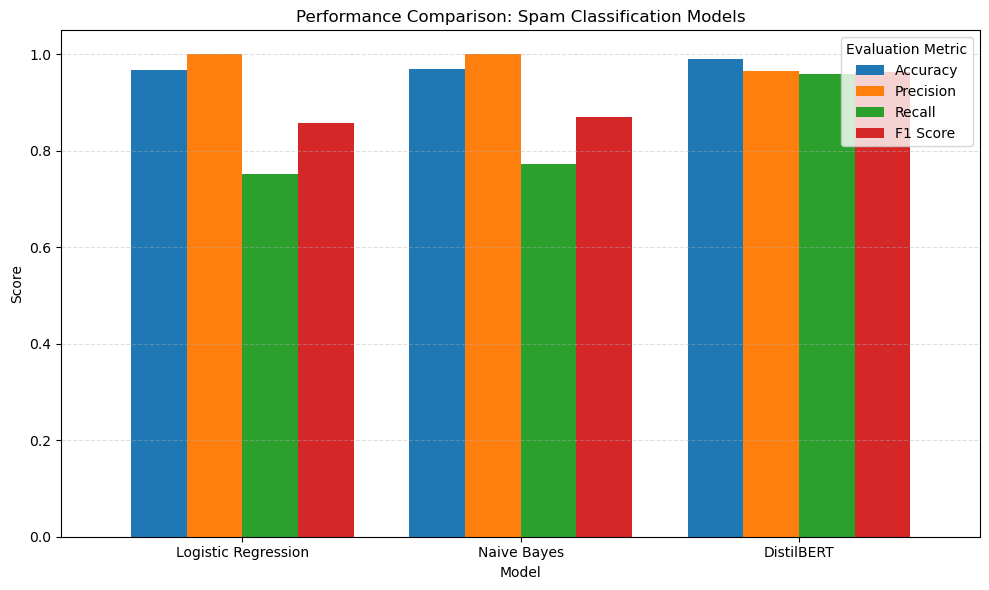

In [71]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd


metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1 Score"]

plot_data = combined_results.set_index("Model")[metrics_to_plot]

plt.figure(figsize=(10, 6))
plot_data.plot(kind="bar", figsize=(10, 6), width=0.8)

plt.title("Performance Comparison: Spam Classification Models")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metric")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

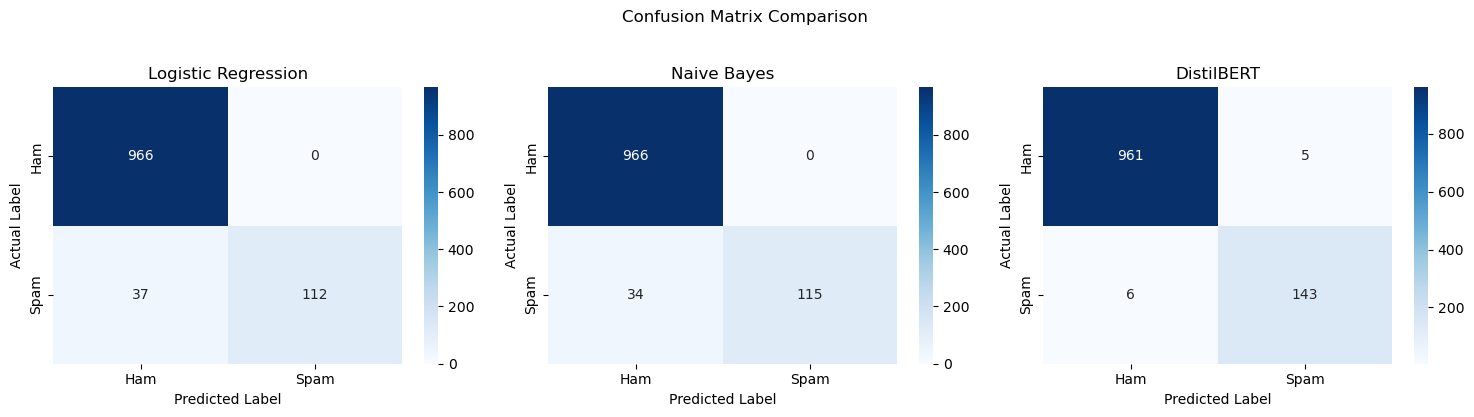

In [72]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

models_to_plot = [
    ("Logistic Regression", y_test, y_pred_lr),
    ("Naive Bayes", y_test, y_pred_nb),
    ("DistilBERT", all_labels, all_predictions)
]

for ax, (name, actual, predicted) in zip(axes, models_to_plot):
    cm = confusion_matrix(actual, predicted, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Ham", "Spam"],
        yticklabels=["Ham", "Spam"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.suptitle("Confusion Matrix Comparison", y=1.03)
plt.tight_layout()
plt.show()

In [75]:
import time

start = time.time()
model_lr.fit(X_train_tfidf, y_train)
lr_training_time = time.time() - start


start = time.time()
model_nb.fit(X_train_tfidf, y_train)
nb_training_time = time.time() - start

print("Logistic Regression:", round(lr_training_time, 2), "seconds")
print("Naive Bayes:", round(nb_training_time, 2), "seconds")
print("DistilBERT:", round(distilbert_training_time, 2), "seconds")

Logistic Regression: 0.12 seconds
Naive Bayes: 0.0 seconds
DistilBERT: 846.44 seconds


In [74]:
print("Possible model variables:")

for name, obj in globals().copy().items():
    if "LogisticRegression" in str(type(obj)) or "MultinomialNB" in str(type(obj)):
        print(name, type(obj).__name__)

Possible model variables:
model_lr LogisticRegression
model_nb MultinomialNB


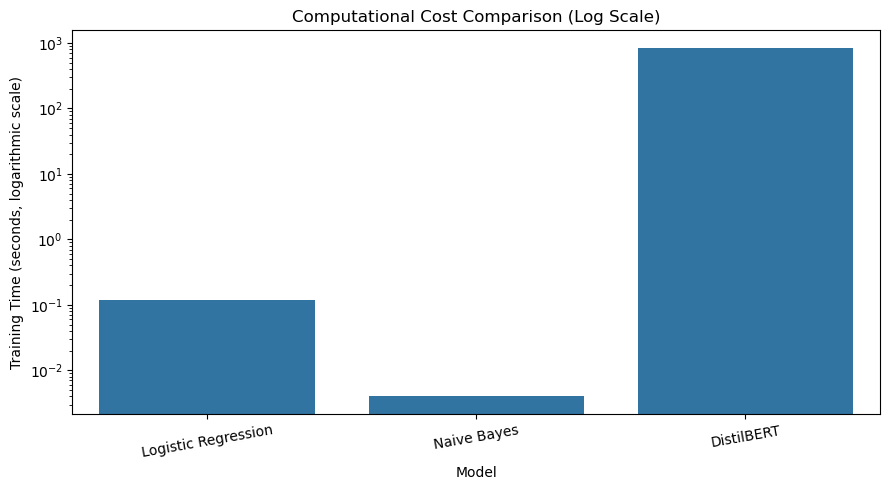

,Model,Training Time (seconds)
0,Logistic Regression,0.12
1,Naive Bayes,0.00
2,DistilBERT,846.44


In [79]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

training_times = pd.DataFrame({
    "Model": ["Logistic Regression", "Naive Bayes", "DistilBERT"],
    "Training Time (seconds)": [
        lr_training_time,
        nb_training_time,
        distilbert_training_time
    ]
})

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=training_times,
    x="Model",
    y="Training Time (seconds)"
)

ax.set_yscale("log")
plt.title("Computational Cost Comparison (Log Scale)")
plt.xlabel("Model")
plt.ylabel("Training Time (seconds, logarithmic scale)")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()
display(training_times.round(2))